# Notebook 003: Initial results with a logistic regression baseline
**CIND 820 Milestone 3 · Canadian Income Survey 2018–2022 · RQ2 (out-of-time testing)**

How to run: open in Google Colab, choose **Runtime → Run all**, and allow Google Drive access when asked.
The notebook reads `ProcessedData/household_table.csv`, which Notebook 01 creates. It does not rebuild that file.

**Draft code was initially prepared by ChatGPT Sol 6.1 and later altered and finalized by Claude (Anthropic) when the author identified the codes were too complicated and lengthy. Claude changed the executable codes to simplify them, and prepared a reusable helper file. Different decisions such as validation metrics, threshold strategy were made and justified by the author, Claude helped refine the wordings. The notes under each step and the final explanations were prepared by the author, Claude provided valuable feedback to make them non-vague and accurate.**

Each code cell imports the libraries it needs at the top, so you can see which library each step uses.

Plan in one paragraph: fit on 2018, check on 2019 and choose the cut-off probability on 2019 only, then refit on 2018 + 2019 and test once each on 2020, 2021 and 2022. Two tracks run side by side, one unweighted and one weighted by FWEIGHT.

## Step 1. Set up, open Drive and load the household table

In [96]:
from pathlib import Path
import platform
import sys

import pandas as pd
import sklearn

# Open Google Drive when running in Colab. Outside Colab this import fails and we simply carry on.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# Same project folder as Notebook 00. Change only if yours is different.
PROJECT_PATH = Path("/content/drive/MyDrive/CIND820_CapstoneProject")
DATA_FILE = PROJECT_PATH / "ProcessedData" / "household_table.csv"
OUTPUT_PATH = PROJECT_PATH / "M3_outputs"
CODE_PATH = PROJECT_PATH / "code"                   # m3_helpers.py has been put in this folder

if not PROJECT_PATH.exists():
    raise FileNotFoundError(f"Cannot find the project folder {PROJECT_PATH}. In Colab, run this cell again and click Allow "
                            "when Google Drive asks for access, then check the folder name.")
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Cannot find {DATA_FILE}. Run Notebook 01 first.")
if not (CODE_PATH / "m3_helpers.py").is_file():
    raise FileNotFoundError(f"Cannot find m3_helpers.py in {CODE_PATH}. Upload it to that folder.")

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)      # exist_ok=True: no error if the folder is already there
sys.path.append(str(CODE_PATH))                     # lets Python import m3_helpers from that folder

hh = pd.read_csv(DATA_FILE)
print("Household table:", hh.shape)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Household table: (201171, 21)
Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


**Purpose:** The purpose of this code block is the set-up the Google Colab environment for analysis.

**What the code does:**
The code block starts by importing the required libraries. Thereafter, it asks to mount the virtual drive to Google Colab with error messages if unsucessful.  The codes help connect the Google Mydrive folder where the raw data file exists and assign folder and file path which had been used later. If the mounting is unsucessful the code is built to show the error message.
Then for the sake of avoiding to type in the entire directory, it assigns the pathways for project folder, data file, out put folder, and the path for the helper file. Noteworthy is that for someone using this Notebook, it also has a mkdir to create a folder for outputs, however, if it already exists, it will not createe it.
To use the helper file it uses the append function so that whenever called the helper file is usable.
It then makes a dataframe called hh which reads and contains the processed data created in Milestone 2, followed by checking the number of rows and columns to make sure data is intact.
Finally, it shows the audience the different versions of the libraries used to execute the code block.  

**My observed result:**
The drive has been mounted and connected to the virtual Google Colab content/drive where the project's working data is hosted.

**Report section:**
Methods and tools

**What would fail if this step were removed:**
This code block will need to be run at the begining of every new session otherwise data will not be accessible in the Google Colab environment and therefore none of the consecutive code blocks will run.  

## Step 2. Decisions fixed before any model is fitted


In [97]:
PREDICTORS = ["income_quintile", "tenure", "has_children", "SEX", "edu_household", "IMMST", "MAJRI", "PROV", "HHSIZE"]
from m3_helpers import TARGET, WEIGHT     # TARGET = "food_insecure" (1 = any food insecurity), WEIGHT = "FWEIGHT" (the earner's weight)

FIT_YEAR = 2018              # first fit
VALID_YEAR = 2019            # check the model and choose the cut-off here
TEST_YEARS = [2020, 2021, 2022]

C_VALUE = 1.0                # regularization strength of the logistic regression (scikit-learn default, no tuning)

# F1 score was used to select the classification threshold because it provides a
# balanced measure of precision and recall on the 2019 validation dataset.
THRESHOLD_METRIC = "f1"

# Columns that must never be predictors, because they contain or come from the outcome
assert TARGET not in PREDICTORS and "FSCHHLDM" not in PREDICTORS and WEIGHT not in PREDICTORS
print("Predictors:", PREDICTORS)

Predictors: ['income_quintile', 'tenure', 'has_children', 'SEX', 'edu_household', 'IMMST', 'MAJRI', 'PROV', 'HHSIZE']


**Purpose:**
The purpose of this code block is to establish all modelling decisions before fitting any machine learning model.

**What the code does:**
The code block starts by identifying the predictor variables that will be used throughout the modelling exercise. These variables were selected during Milestone 2 and include household income quintile, housing tenure, presence of children, sex, education level, immigration status, major source of income, province of residence and household size.

Thereafter, it imports the outcome variable and survey weight variable from the helper file so they can be used consistently throughout the notebook. The code then assigns the years that will be used for model development. Specifically, 2018 is assigned as the initial training year, 2019 is assigned as the validation year and 2020 to 2022 are assigned as the future testing years.

The code also defines the regularization setting for the logistic regression model and sets the performance measure that will be used later when selecting the classification threshold. In this notebook, the F1 score is chosen as the criterion for selecting the optimal threshold.

Finally, the code contains several validation checks using assertions. These checks make sure that the outcome variable, the original source of the outcome variable and the survey weight variable have not accidentally been included among the predictor variables, which would introduce data leakage into the model.

**My observed result:**
The predictor variables, outcome variable, survey weight variable, analysis years and threshold selection rule were successfully defined. The output displayed the nine predictor variables that will be used throughout the modelling process and no assertion errors were returned.

**Report section:**
Methods and validation protocol.

**What would fail if this step were removed:**
Without this code block, the notebook would not know which variables should be used as predictors, which variable should be treated as the outcome, or which years belong to training, validation and testing. As a result, the model development process would either fail to run or use inconsistent settings across different parts of the notebook. The checks designed to prevent accidental data leakage would also be lost.

## Step 3. Check the table against Milestone 2, and look at the outcome by year

In [98]:
import numpy as np
import pandas as pd

# Household counts from the Milestone 2 report (Table 1)
EXPECTED_COUNTS = {2018: 39481, 2019: 30712, 2020: 52235, 2021: 38015, 2022: 40728}

counts = hh.groupby("YEAR").size().to_dict()
print("Counts match Milestone 2:", counts == EXPECTED_COUNTS)
assert counts == EXPECTED_COUNTS, "Household counts differ from the report. Stop and find out why."
assert not hh.duplicated(["YEAR", "PUMFID"]).any(), "A household appears twice."
assert hh[TARGET].isin([0, 1]).all()

rows = []
for year, g in hh.groupby("YEAR"):
    rows.append({
        "YEAR": year,
        "households": len(g),
        "food_insecure_n": int(g[TARGET].sum()),
        "unweighted_pct": round(100 * g[TARGET].mean(), 2),
        "weighted_pct": round(100 * np.average(g[TARGET], weights=g[WEIGHT]), 2),
    })
outcome_by_year = pd.DataFrame(rows)
outcome_by_year

Counts match Milestone 2: True


,YEAR,households,food_insecure_n,unweighted_pct,weighted_pct
0,2018,39481,6434,16.30,16.04
1,2019,30712,4514,14.70,15.68
2,2020,52235,7247,13.87,15.81
3,2021,38015,6039,15.89,17.63
4,2022,40728,8279,20.33,22.41


**Purpose:**
The purpose of this code block is to double check the processed data created during Milestone 2 to ensure that it matches the data that will be used for model development and evaluation. This check is performed before any model fitting so we are working with the intended analytical data set.

**What the code does:**
The code block starts by defining the expected number of households for each survey year based on the counts previously reported in Milestone 2. These values are stored in the EXPECTED_COUNTS dictionary and act as a benchmark against which the current processed data is compared. Thereafter, the code uses, `counts = hh.groupby("YEAR").size().to_dict() to calculate the current household counts by survey year and compare them with the expected values. This serves as a quality control check to ensure that household row counts remain unchanged between Milestone 2 and Milestone 3.

The code then performs additional data integrity checks using the assert function. Specifically, it verifies that no household appears more than once within the same survey year by checking the unique household identifier (PUMFID) and confirms that the outcome variable contains only two valid categories, namely food secure (0) and food insecure (1).

Finally, the code creates a summary table showing the total number of households, number of food insecure households, unweighted percentage of food insecurity, and weighted percentage of food insecurity for each survey year. The weighted percentage is calculated using the np.average() function together with the survey weight variable (FWEIGHT). This summary allows the audience to understand the distribution of the outcome variable before any machine learning model is fitted.

**My observed result:**
The household counts matched the values previously reported in Milestone 2 for all five survey years and all assertion checks passed successfully.

The number of households available for analysis was 39,481 in 2018, 30,712 in 2019, 52,235 in 2020, 38,015 in 2021 and 40,728 in 2022.

The summary table also showed that the unweighted percentage of food insecurity ranged from 13.87% in 2020 to 20.33% in 2022. The weighted percentage was slightly lower than the unweighted percentage in 2018, but higher than the unweighted percentage in 2019 through 2022.

Among the five survey years, 2022 had the highest prevalence of food insecurity while 2019 and 2020 had the lowest prevalence based on the unweighted percentages.

**Report section:**
Data preparation and descriptive analysis.

**What would fail if this step were removed:**
Without this code block, the consecutive code blocks would not fail since this is a data integrity check only. However, we would fail to confirm that we are using the same processed data that was created in Milestone 2 and intended for the remaining analyses. As a result, unexpected issues such as missing records, duplicate households, or incorrectly coded outcome values could go unnoticed before model development begins.

## Step 4. Split by year, never at random
Rows are never shuffled. Earlier years fit the model and later years test it, so the test never helps build the model.

In [99]:
fit_df = hh[hh["YEAR"] == FIT_YEAR].copy()
valid_df = hh[hh["YEAR"] == VALID_YEAR].copy()
dev_df = hh[hh["YEAR"].isin([FIT_YEAR, VALID_YEAR])].copy()      # development data = 2018 + 2019
test_dfs = {y: hh[hh["YEAR"] == y].copy() for y in TEST_YEARS}

assert dev_df["YEAR"].max() < min(TEST_YEARS), "Test years must come after the development years."
print("Fit:", len(fit_df), "| Validation:", len(valid_df), "| Development:", len(dev_df))
print("Test:", {y: len(d) for y, d in test_dfs.items()})

Fit: 39481 | Validation: 30712 | Development: 70193
Test: {2020: 52235, 2021: 38015, 2022: 40728}



**Purpose:**
The purpose of this code block is to create the training, validation and testing datasets according to the analysis plan established in Step 2. This ensures that future survey years are not used during model development and remain available for independent evaluation of model performance.

**What the code does:**
The code block starts by separating the household table into individual datasets based on the survey year. Using `fit_df = hh[hh["YEAR"] == FIT_YEAR].copy()` it creates the initial training dataset using only the 2018 service cycle you can learn more from ([here](https://www.datacamp.com/tutorial/settingwithcopywarning-pandas)). Similarly, this line of code (where VALID actually stands for validation) `valid_df = hh[hh["YEAR"] == VALID_YEAR].copy()` creates the validation dataset using only the 2019 service cycle. These variables were defined in step 2 (for learning more click [here](https://www.dataquest.io/blog/filtering-pandas-dataframes/)).
Moving forward, the next code, i.e., `dev_df = hh[hh["YEAR"].isin([FIT_YEAR, VALID_YEAR])].copy()` combines 2018 and 2019 datasets to create a development dataset (for more on `is.in` function click [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html) ) . This dataset will later be used to refit the final model after the optimal classification threshold has been selected on the validation data.
The code then creates separate testing datasets for 2020, 2021 and 2022 using:
`test_dfs = {y: hh[hh["YEAR"] == y].copy() for y in TEST_YEARS}` (for more on this code, go to the panda's official site here and look for [Boolean Index section](https://pandas.pydata.org/docs/user_guide/indexing.html)). This allows each future survey year to be evaluated independently after model development is complete.

Unlike many machine learning examples that randomly split observations into training and testing groups, this study uses survey years to separate datasets. Earlier years are used for model development while later years remain unseen until final testing. This approach mirrors how a model would be used in practice, where future outcomes are predicted using information available from previous years.

Finally, the code uses the assertion using the code `assert dev_df["YEAR"].max() < min(TEST_YEARS)` to confirm that all development years occur before the testing years (you can learn more from [here](https://www.programiz.com/python-programming/assert-statement)). This serves as an additional safeguard against accidental leakage of future information into the model development process.

**My observed result:**
The code successfully created four groups of data consisting of a 2018 training dataset, a 2019 validation dataset, a combined 2018-2019 development dataset, and three independent testing datasets representing the 2020, 2021 and 2022 service cycles.

The output showed 39,481 households in the training dataset, 30,712 households in the validation dataset, and 70,193 households in the combined development dataset.

The testing datasets contained 52,235 households in 2020, 38,015 households in 2021, and 40,728 households in 2022.

The assertion check passed successfully, confirming that all testing years occurred after the development years and therefore preserving the intended out-of-time validation design

**Report section:**
Validation protocol and model development.

**What would fail if this step were removed:**
Without this code block, the notebook would still contain the full household table, but there would be no separation between training, validation and testing data. As a result, the validation protocol described in the report could not be implemented and future survey years could inadvertently influence model development. The study would therefore lose its ability to perform a meaningful out-of-time evaluation of model performance.


## Step 5. Descriptive statistics, histograms and boxplots (development years only)
`adj_income` is household income divided by the square root of household size. `HHSIZE` is the household size code (1 to 7; the data dictionary lists the codes 01 to 07 and does not say whether 7 means seven or more).
These summaries are unweighted. Outliers are flagged, not removed. The mode of a dollar amount is rarely meaningful (almost every value is different), so read it for HHSIZE and treat the income mode with caution.

In [100]:
import pandas as pd

for var in ["adj_income", "HHSIZE"]:
    rows = []
    for year, g in dev_df.groupby("YEAR"):
        s = g[var].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        rows.append({
            "YEAR": year, "n": len(s), "mean": s.mean(), "median": s.median(),
            "mode": s.mode().iloc[0], "variance": s.var(),
            "outside_1.5_IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            "zero_or_negative": int((s <= 0).sum()),
        })
    print(var)
    display(pd.DataFrame(rows).round(2))

adj_income


,YEAR,n,mean,median,mode,variance,outside_1.5_IQR,zero_or_negative
0,2018,39481,51109.61,44875.0,20800.0,1.074872e+09,1435,58
1,2019,30712,53077.42,46616.4,22000.0,1.142755e+09,1148,46


HHSIZE


,YEAR,n,mean,median,mode,variance,outside_1.5_IQR,zero_or_negative
0,2018,39481,2.30,2.0,2,1.61,201,0
1,2019,30712,2.28,2.0,2,1.60,161,0


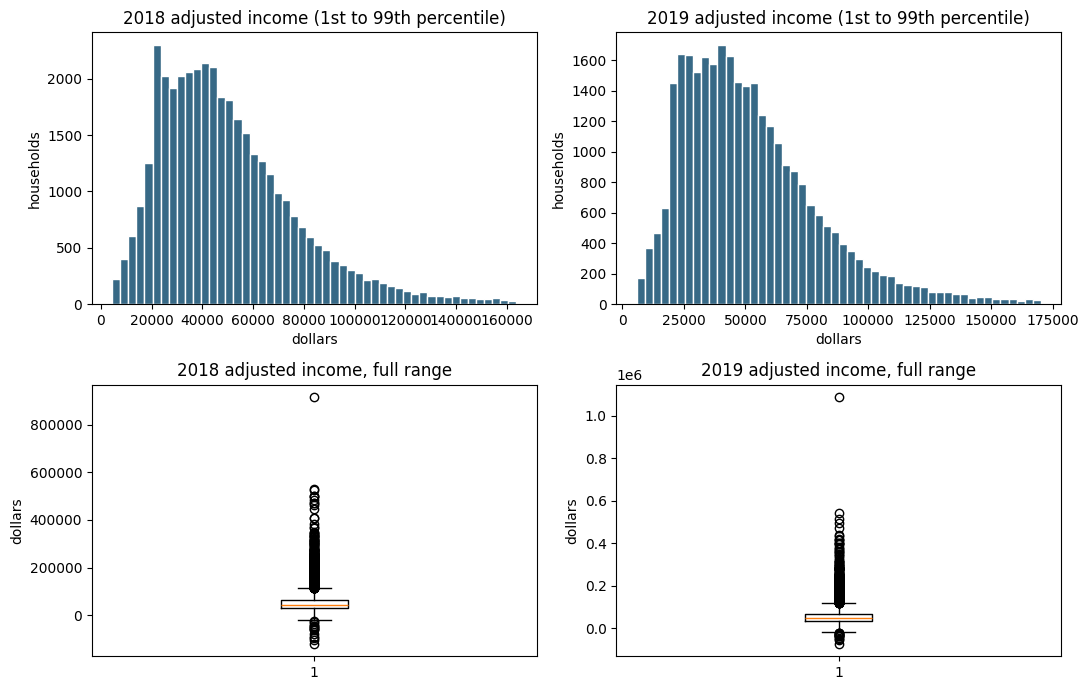

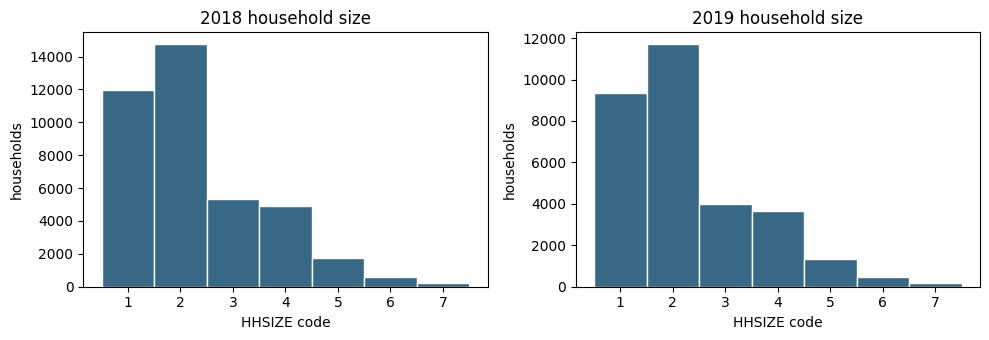

In [101]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, year in enumerate([2018, 2019]):
    s = dev_df.loc[dev_df["YEAR"] == year, "adj_income"].dropna()
    low, high = s.quantile(0.01), s.quantile(0.99)
    axes[0, col].hist(s[(s >= low) & (s <= high)], bins=50, color="#376986", edgecolor="white")
    axes[0, col].set(title=f"{year} adjusted income (1st to 99th percentile)", xlabel="dollars", ylabel="households")
    axes[1, col].boxplot(s)           # the boxplot shows the full range, so the outliers are visible
    axes[1, col].set(title=f"{year} adjusted income, full range", ylabel="dollars")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "adj_income_hist_box.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for col, year in enumerate([2018, 2019]):
    s = dev_df.loc[dev_df["YEAR"] == year, "HHSIZE"].dropna()
    axes[col].hist(s, bins=np.arange(0.5, 8.5, 1), color="#376986", edgecolor="white")
    axes[col].set(title=f"{year} household size", xlabel="HHSIZE code", ylabel="households")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "hhsize_hist.png", dpi=150)
plt.show()

**Purpose:**
The purpose of this code block is to explore the distribution of the two numerical variables used in the model development dataset, namely adjusted household income and household size. This step helps identify patterns such as skewness, variability, and potential outliers before fitting the logistic regression model.

**What the code does:**
The code block starts by creating descriptive statistics for the variables adj_income and HHSIZE using only the development years (2018 and 2019). For each variable and year, the code calculates the sample size, mean, median, mode and variance.

Thereafter, the code calculates the first quartile (Q1), third quartile (Q3) and the interquartile range (IQR). Using the standard boxplot rule, it counts the number of observations falling outside 1.5 × IQR with the code `((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()`. The code also identifies the number of households reporting zero or negative values using: `(s <= 0).sum()`. Finally, the code produces histograms and boxplots for adjusted household income and histograms for household size for both 2018 and 2019 using the standard `matplotlib`. For the income histograms, only the 1st to 99th percentile range is displayed in order to make the main body of the distribution easier to interpret visually, while the corresponding boxplots retain the full range so that potential outliers remain visible.

**My observed result:**
Descriptive statistics were produced for adjusted household income and household size for the 2018 and 2019 development years.
For adjusted income, the mean was higher than the median in both years. In 2018, the mean adjusted income was 51,109.61 dollars while the median was 44,875.00 dollars. In 2019, the mean was 53,077.42 dollars and the median was 46,616.40 dollars. This pattern suggests that adjusted income follows a right-skewed distribution where a relatively small number of households with very high incomes pull the mean upward.
Using the 1.5 × IQR rule, 1,435 households in 2018 and 1,148 households in 2019 were flagged as outliers. These represented approximately 3.6% and 3.7% of households respectively. Given the skewed income distribution, many of these flagged observations are likely to represent genuine high household incomes rather than data errors. In comparison, only 58 households in 2018 and 46 households in 2019 reported zero or negative adjusted income.
For household size, both the median and the mode were equal to 2 in 2018 and 2019. The mean household size was also similar between years at 2.30 in 2018 and 2.28 in 2019. Variance values of 1.61 and 1.60 suggest that household size was concentrated within a fairly narrow range and remained stable across the two development years. It should be noted that HHSIZE is coded from 1 to 7, therefore the mean and variance should be interpreted only as rough summaries of the distribution.
Although skewness and outliers were observed in the raw income values, the model itself does not use raw adjusted income. Instead, it uses the categorical variable income_quintile, while household size is also treated as a categorical predictor. As a result, extreme income values and skewed distributions are less likely to influence the logistic regression model directly.
Overall, the descriptive statistics indicate that adjusted income contains noticeable skewness and some extreme values, whereas household size appears stable and less dispersed across both development years.


*Interpretation of Figures 1 and 2:*
The histograms for adjusted household income in both 2018 and 2019 show that most households are concentrated in the lower and middle income ranges, followed by a long tail extending toward higher income values. This visual pattern supports the results presented in Table 2, where the mean income was greater than the median in both years.

It should be noted that the histogram titles indicate that only observations between the 1st and 99th percentiles were displayed. This was done to improve visualization of the main distribution and prevent a small number of extreme values from compressing the scale of the graph.

The 2018 histogram also shows a small concentration of households near the 20,000-dollar range, which is consistent with the reported mode of 20,800 dollars.

The boxplots display the full range of adjusted income values and reveal a large number of observations beyond the upper whisker. The boxplots also show a small number of observations below the lower whisker, corresponding to a subset of households with negative adjusted income identified in Table 2. The highest observed adjusted income values approach 0.9 million dollars in 2018 and exceed 1 million dollars in 2019, illustrating the presence of a small number of very high-income households.

The household size histograms show a strong concentration around HHSIZE codes of 1 and 2, with fewer households observed as household size increases. A very similar pattern is visible in both 2018 and 2019, suggesting that the distribution of household size remained stable across the two development years.

Overall, the figures support the findings from Table 2. Adjusted household income exhibits a right-skewed distribution with a small number of very high-income households, whereas household size appears concentrated within a narrow range and shows little change between the two development years.


**Report section:**
Descriptive statistics and exploratory data analysis.

**What would fail if this step were removed:**
The remaining code blocks would still run because this step is exploratory rather than required for model fitting. However, we would lose an important understanding of the data distributions before modelling. Potential issues such as skewed income distributions, unusual observations, and the overall variability of key predictors would be less apparent, making later interpretation of the model results more difficult.

## Step 6. Helper functions (in `m3_helpers.py`)
The functions live in a separate file, `m3_helpers.py`, so this notebook stays readable and the code can be reused in Milestone 4. Open that file to read them.
- `make_X` turns the nine coded predictors into text labels, so each is treated as a category (one-hot encoding), not as a number. Missing values become their own category, "Missing".
- `fit_model` puts the encoder and the logistic regression in one pipeline, so the encoder learns its categories only from the data we fit on. That is how the leakage rule is kept.
- `predict_prob` gives each household's predicted probability of food insecurity.
- `confusion_scores` and `all_scores` give the confusion matrix and the metrics at one cut-off.
- `best_threshold` tries cut-offs from 0.05 to 0.95 and keeps the best one for the chosen metric.

In [102]:
from m3_helpers import make_X, fit_model, predict_prob, confusion_scores, all_scores, best_threshold
print("Helper functions loaded from", CODE_PATH / "m3_helpers.py")

Helper functions loaded from /content/drive/MyDrive/CIND820_CapstoneProject/code/m3_helpers.py


**Purpose:**
This code block is to load the helper functions that will be used throughout the remainder of the notebook. Moving these functions into a separate file helps keep the notebook organized and allows the same functions to be reused later in Milestone 4.

**What the code does:**
The code block imports the helper functions stored in the m3_helpers.py file utilizing the code `from m3_helpers import make_X, fit_model, predict_prob, confusion_scores, all_scores, best_threshold`

The make_X function converts the predictor variables into text labels and replaces missing values with the category "Missing". The actual one-hot encoding is performed later inside the modelling pipeline.

The fit_model function fits both the encoder and the logistic regression model together in a single pipeline. The encoder learns its categories only from the data provided to the function, helping prevent information leakage from validation or test datasets. The function also applies FWEIGHT when fitting the weighted version of the model.

The predict_prob function generates predicted probabilities of food insecurity for each household.

The confusion_scores function calculates the confusion matrix and classification measures at a given threshold. The all_scores function extends this by calculating additional performance measures including accuracy, precision, recall, specificity, F1 score, ROC-AUC and PR-AUC. Unlike the confusion matrix measures, ROC-AUC and PR-AUC do not depend on a classification threshold.

Finally, the best_threshold function evaluates thresholds from 0.05 to 0.95 and identifies the threshold that produces the highest value for the performance metric selected in Step 2.

Once imported, these functions become available for use throughout the remaining modelling, validation and testing steps.

**My observed result:**
The helper functions were imported from the m3_helpers.py file without any errors. The output displayed the location of the helper file in the project's code folder, confirming that the required functions had been loaded and were available for the remaining analysis.

**Report section:**
Methods and tools. Helper functions are also described in the README file.

**What would fail if this step were removed:**
Without this code block, the notebook would not recognize the custom functions used throughout the remaining analysis. As a result, later steps involving data preparation, model fitting, prediction, threshold selection and performance evaluation would fail because the required functions would not be available.

## Step 7. Fit on 2018, check on 2019, choose the cut-off on 2019
Two tracks. **Unweighted:** every household counts once, scores are plain counts. **Weighted:** households count by FWEIGHT, scores use FWEIGHT.
Weighted results are working estimates, not official household estimates.

In [103]:
from datetime import datetime
import pandas as pd

TRACKS = {"unweighted": False, "weighted": True}
thresholds = {}
valid_probs = {}
rows = []

for track, use_w in TRACKS.items():
    model = fit_model(fit_df, use_w, PREDICTORS, C_VALUE)                  # 2018 only
    prob = predict_prob(model, valid_df, PREDICTORS)
    valid_probs[track] = prob
    w = valid_df[WEIGHT] if use_w else None
    thresholds[track] = best_threshold(valid_df[TARGET], prob, w, THRESHOLD_METRIC)
    for label, t in [("cut-off 0.50 (reference)", 0.5), (f"cut-off maximizing {THRESHOLD_METRIC}", thresholds[track])]:
        rows.append({"track": track, "rule": label, **all_scores(valid_df[TARGET], prob, t, w)})

validation_table = pd.DataFrame(rows)
cols = ["track", "rule", "threshold", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc"]
display(validation_table[cols].round(3))
validation_table.to_csv(OUTPUT_PATH / "validation_2019.csv", index=False)

# Record the cut-offs BEFORE any test year is scored
with open(OUTPUT_PATH / "frozen_thresholds.txt", "w") as f:
    f.write(f"Written {datetime.now()} before 2020-2022 were scored\n")
    f.write(f"metric={THRESHOLD_METRIC} C={C_VALUE} thresholds={thresholds}\n")
print("Frozen cut-offs:", thresholds)

,track,rule,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,unweighted,cut-off 0.50 (reference),0.50,0.854,0.528,0.090,0.986,0.154,0.772,0.36
1,unweighted,cut-off maximizing f1,0.23,0.775,0.340,0.565,0.811,0.424,0.772,0.36
2,weighted,cut-off 0.50 (reference),0.50,0.844,0.518,0.077,0.987,0.134,0.765,0.36
3,weighted,cut-off maximizing f1,0.25,0.783,0.363,0.509,0.834,0.424,0.765,0.36


Frozen cut-offs: {'unweighted': 0.23, 'weighted': 0.25}


**Purpose:**
The purpose of this code block is to fit the initial logistic regression model using the 2018 training data, evaluate its performance on the independent 2019 validation data, and select the classification threshold that maximizes the pre-specified F1 score. This step is completed before any testing on the 2020-2022 data.

**What the code does:**
The code block starts by creating two analysis tracks:

Unweighted, where each household contributes equally to model fitting and evaluation.
Weighted, where households contribute according to the survey weight (FWEIGHT).

For each track, the `fit_model()` function fits a logistic regression model using the 2018 training data only. The fitted model is then applied to the 2019 validation data using: `prob = predict_prob(model, valid_df, PREDICTORS)` which
generates predicted probabilities of food insecurity for each household See [this page](https://www.datacamp.com/tutorial/understanding-logistic-regression-python) for more.
The next code, `thresholds[track] = best_threshold(...)`, serves the purpose of searching classification thresholds between 0.05 and 0.95 and identify the threshold that maximizes the F1 score on the validation data. Performance at the conventional reference threshold of 0.50 is also calculated for comparison.

Using the all_scores() function, the code calculates accuracy, precision, recall, specificity, F1 score, ROC-AUC and PR-AUC for both the reference threshold and the threshold selected by the optimization procedure.
Finally, this step, `frozen_thresholds.txt`writes the thresholds to a text file before any 2020-2022 test data are scored. This creates a permanent record of the thresholds selected on the validation year and helps ensure that later testing does not influence model development decisions.


**My observed result:**
Validation results were produced separately for the unweighted and weighted analysis tracks.

For the unweighted track, the conventional threshold of 0.50 produced an accuracy of 0.854, precision of 0.528, recall of 0.090 and an F1 score of 0.154. The very low recall indicates that relatively few food-insecure households were being identified at this threshold. After optimizing the threshold on the 2019 validation data, the selected threshold was 0.23. At this threshold, recall increased from 0.090 to 0.565 and the F1 score increased from 0.154 to 0.424. This improvement came at the expense of lower precision, which decreased from 0.528 to 0.340, and lower specificity, which decreased from 0.986 to 0.811.

For the weighted track, the conventional threshold of 0.50 produced an accuracy of 0.844, precision of 0.518, recall of 0.077 and an F1 score of 0.134. Similar to the unweighted results, the low recall indicates that relatively few food-insecure households were being identified at the reference threshold. The threshold maximizing the F1 score was 0.25. Using this threshold increased recall from 0.077 to 0.509 and increased the F1 score from 0.134 to 0.424. This improvement came at the expense of lower precision, which decreased from 0.518 to 0.363, and lower specificity, which decreased from 0.987 to 0.834.

ROC-AUC and PR-AUC remained unchanged within each track because these measures evaluate the ranking ability of the model and do not depend on the classification threshold selected.

The final thresholds selected on the 2019 validation data were 0.23 for the unweighted analysis and 0.25 for the weighted analysis. The step then writes these thresholds to frozen_thresholds.txt before any 2020-2022 data are scored. This creates a record of the threshold values used for subsequent testing.

*Interpretation of the Graph in 7b below*
The ROC curves produced ROC-AUC values of 0.772 for the unweighted analysis and 0.765 for the weighted analysis. Both curves remained well above the no-skill reference line, indicating that the model was able to distinguish between food-secure and food-insecure households substantially better than random classification.

For the unweighted analysis, the threshold maximizing Youden's J statistic was approximately 0.14, while the threshold selected in Step 7 by maximizing the F1 score was 0.23. The Youden's J point achieved a recall of approximately 0.77 but at the cost of a false positive rate of approximately 0.36. In contrast, the F1-selected threshold achieved a recall of 0.565 with a false positive rate of approximately 0.19. This means that the Youden's J threshold would identify more food-insecure households but would also incorrectly flag substantially more food-secure households.

For the weighted analysis, a similar pattern was observed. The Youden's J threshold was approximately 0.13, while the threshold maximizing the F1 score was 0.25. The Youden's J point achieved a recall of approximately 0.77 with a false positive rate of approximately 0.37. In contrast, the F1-selected threshold achieved a recall of approximately 0.51 with a false positive rate of approximately 0.17. As in the unweighted analysis, the Youden's J threshold would identify more food-insecure households but would do so at the cost of substantially more false positive classifications.

The difference between the two methods reflects the fact that F1 score incorporates both precision and recall, whereas Youden's J depends only on recall and specificity. As a result, the two approaches favour different trade-offs when selecting a classification threshold.

Overall, the ROC plots show that the F1-based threshold selected in Step 7 and the Youden's J threshold identify different operating points on the same ROC curve. The plots therefore provide a visual illustration of how different threshold-selection rules can lead to different balances between identifying food-insecure households and incorrectly flagging food-secure households.


**Report section:**
Validation analysis and threshold selection strategy.

**What would fail if this step were removed:**
Without this code block, no validation-year performance assessment would be performed and there would be no evidence-based method for selecting a classification threshold. The later testing stages would either have to rely on an arbitrary threshold or would risk selecting a threshold after examining the test results, which would compromise the independence of the out-of-time evaluation.

### Step 7b. ROC curve on 2019 (the ROC way of looking at cut-offs)
This step is the ROC plot of the Step 7 validation. There is no Step 7a.
The ROC curve shows recall against the false positive rate (1 - specificity) for every possible cut-off. It does not choose a cut-off by itself.
Youden's J picks the point farthest above the diagonal, where recall + specificity - 1 is largest. ROC-AUC (area under the curve) does not depend on any cut-off.

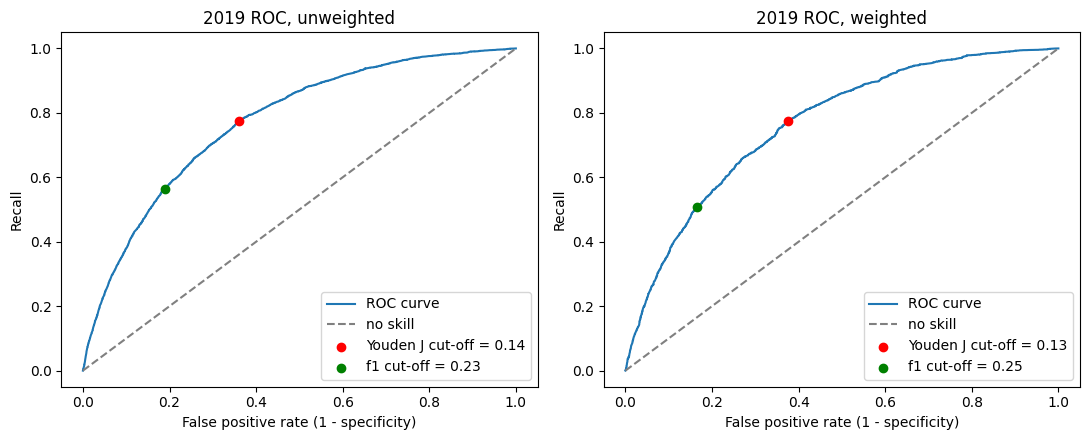

In [104]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (track, use_w) in zip(axes, TRACKS.items()):
    w = valid_df[WEIGHT] if use_w else None
    fpr, tpr, cuts = roc_curve(valid_df[TARGET], valid_probs[track], sample_weight=w)
    j = tpr - fpr                                  # Youden's J = recall + specificity - 1
    k = j.argmax()
    ax.plot(fpr, tpr, label="ROC curve")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="no skill")
    ax.scatter(fpr[k], tpr[k], color="red", zorder=3, label=f"Youden J cut-off = {cuts[k]:.2f}")
    chosen = confusion_scores(valid_df[TARGET], valid_probs[track], thresholds[track], w)
    ax.scatter(1 - chosen["specificity"], chosen["recall"], color="green", zorder=3,
               label=f"{THRESHOLD_METRIC} cut-off = {thresholds[track]:.2f}")
    ax.set(title=f"2019 ROC, {track}", xlabel="False positive rate (1 - specificity)", ylabel="Recall")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "roc_2019.png", dpi=150)
plt.show()

## Step 8. Refit on 2018 + 2019 and test once on 2020, 2021 and 2022
The cut-offs from Step 7 are used unchanged. Nothing is tuned on these years.

In [105]:
import numpy as np
import pandas as pd

final_models = {track: fit_model(dev_df, use_w, PREDICTORS, C_VALUE) for track, use_w in TRACKS.items()}

rows = []
test_matrices = {}
for track, use_w in TRACKS.items():
    for year, df in test_dfs.items():
        prob = predict_prob(final_models[track], df, PREDICTORS)
        w = df[WEIGHT] if use_w else None
        result = all_scores(df[TARGET], prob, thresholds[track], w)
        rows.append({"YEAR": year, "track": track, "n": len(df), **result})
        test_matrices[(track, year)] = np.array([[result["TN"], result["FP"]], [result["FN"], result["TP"]]])

test_table = pd.DataFrame(rows)
cols = ["YEAR", "track", "n", "threshold", "accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc"]
display(test_table[cols].round(3))
test_table.to_csv(OUTPUT_PATH / "test_2020_2022.csv", index=False)

,YEAR,track,n,threshold,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc
0,2020,unweighted,52235,0.23,0.785,0.323,0.502,0.830,0.393,0.759,0.334
1,2021,unweighted,38015,0.23,0.772,0.342,0.468,0.830,0.395,0.740,0.340
2,2022,unweighted,40728,0.23,0.753,0.405,0.455,0.829,0.429,0.734,0.398
3,2020,weighted,52235,0.25,0.772,0.346,0.497,0.824,0.408,0.750,0.347
4,2021,weighted,38015,0.25,0.764,0.367,0.469,0.827,0.412,0.739,0.358
5,2022,weighted,40728,0.25,0.748,0.438,0.441,0.837,0.439,0.737,0.431


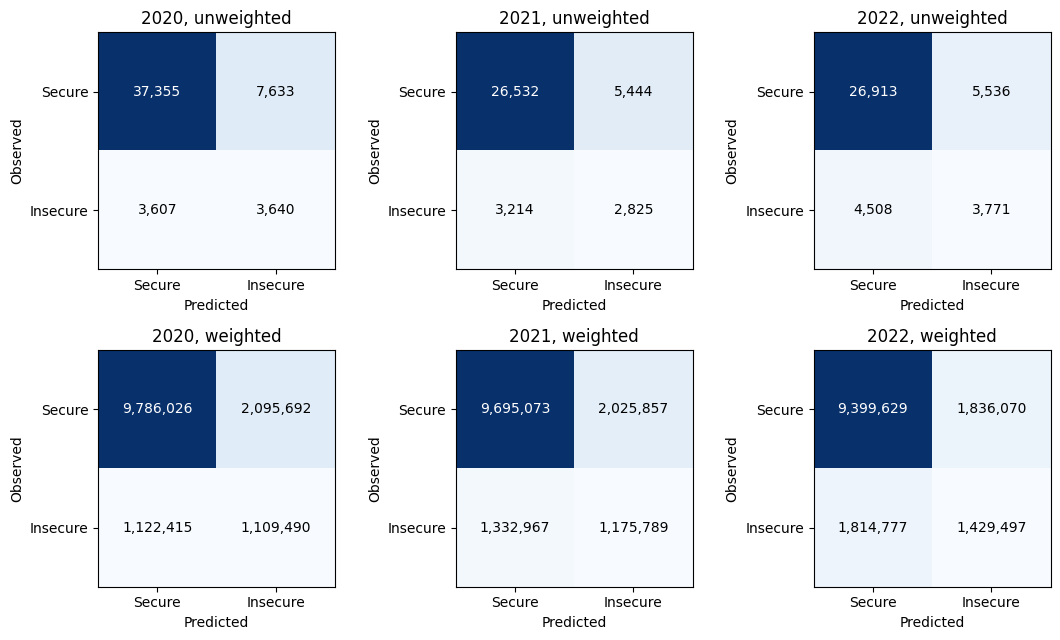

In [106]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for r, track in enumerate(TRACKS):
    for c, year in enumerate(TEST_YEARS):
        m = test_matrices[(track, year)]
        ax = axes[r, c]
        ax.imshow(m, cmap="Blues")
        ax.set(title=f"{year}, {track}", xticks=[0, 1], yticks=[0, 1],
               xticklabels=["Secure", "Insecure"], yticklabels=["Secure", "Insecure"],
               xlabel="Predicted", ylabel="Observed")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{m[i, j]:,.0f}", ha="center", va="center",
                        color="white" if m[i, j] > m.max() / 2 else "black")
plt.tight_layout()
plt.savefig(OUTPUT_PATH / "confusion_matrices_test.png", dpi=150)
plt.show()

In [107]:
# Check one number by hand: recall for the unweighted track in 2022 = TP / (TP + FN)
row = test_table[(test_table["YEAR"] == 2022) & (test_table["track"] == "unweighted")].iloc[0]
by_hand = row["TP"] / (row["TP"] + row["FN"])
print(f"2022 recall = {row['TP']:,.0f} / ({row['TP']:,.0f} + {row['FN']:,.0f}) = {by_hand:.4f}  (table says {row['recall']:.4f})")
assert abs(by_hand - row["recall"]) < 1e-9

2022 recall = 3,771 / (3,771 + 4,508) = 0.4555  (table says 0.4555)


**Purpose:**
The purpose of this code block is to refit the logistic regression model using all available development data (2018 and 2019), apply the thresholds selected during validation, and evaluate how well the model performs on the independent test years (2020-2022). This step provides the final assessment of model performance on future data that were not used for model development.

**What the code does:**
The code block starts by fitting the final logistic regression models using the combined development dataset, which contains both the 2018 training data and the 2019 validation data. Separate models are fitted for the unweighted and weighted analysis tracks.

Thereafter, the code uses the fitted models to generate predicted probabilities of food insecurity for each household in the 2020, 2021 and 2022 test datasets. The frozen thresholds selected in Step 7 (0.23 for the unweighted analysis and 0.25 for the weighted analysis) are then applied to convert predicted probabilities into food secure and food insecure classifications.

The code calculates accuracy, precision, recall, specificity, F1 score, ROC-AUC and PR-AUC for each test year. It also creates confusion matrices for each year and analysis track, allowing the numbers of true positives, true negatives, false positives and false negatives to be visualized and reviewed.

Finally, the code manually recalculates the 2022 unweighted recall using the values from the confusion matrix and compares the result with the value reported in the results table. An assertion is then used to confirm that both values match exactly, serving as a quality-control check on the evaluation calculations

**My observed result:**
The model was evaluated on three independent test years using the thresholds selected during validation.

For the unweighted analysis, accuracy decreased slightly from 0.785 in 2020 to 0.753 in 2022. Recall also decreased from 0.502 in 2020 to 0.455 in 2022. In contrast, precision increased from 0.323 in 2020 to 0.405 in 2022, while the F1 score increased from 0.393 to 0.429. Specificity remained stable at approximately 0.83 across all three years.

For the weighted analysis, a similar pattern was observed. Accuracy declined from 0.772 in 2020 to 0.748 in 2022. Recall decreased from 0.497 to 0.441, while precision increased from 0.346 to 0.438. The F1 score improved from 0.408 in 2020 to 0.439 in 2022. Specificity again remained relatively stable, ranging from 0.824 to 0.837.

ROC-AUC values were fairly stable but showed a small decline across the test years. For the unweighted analysis, ROC-AUC decreased from 0.759 in 2020 to 0.734 in 2022. A similar pattern was observed for the weighted analysis, where ROC-AUC decreased from 0.750 to 0.737. Recall also declined modestly over time for both analysis tracks. These results suggest that the model's ability to distinguish between food-secure and food-insecure households remained reasonably consistent, although performance appears to have weakened slightly in the later years.

PR-AUC values increased in 2022 for both analysis tracks. This likely reflects the higher prevalence of food insecurity observed in 2022 (20.33%) compared with 2020 (13.87%) rather than a substantial improvement in the model itself. A similar interpretation may apply to the increases observed in precision and F1 score.

From the perspective of the research question, recall is particularly important because it reflects the model's ability to identify households that were actually food insecure. In the 2022 unweighted analysis, the model missed more than half of the food-insecure households, highlighting an important limitation when the goal is to identify vulnerable households.

As a final quality-control check, the code manually recalculated the 2022 unweighted recall using the confusion matrix values. For this year, the model correctly identified 3,771 food-insecure households (True Positives, TP) and missed 4,508 food-insecure households (False Negatives, FN). Recall is calculated as TP / (TP + FN), therefore recall = 3,771 / (3,771 + 4,508) = 0.4555. This matched the recall value reported in the results table to within rounding error, confirming that the evaluation metrics were being calculated correctly

**Report section:**
Out-of-time model evaluation and test-year performance.

**What would fail if this step were removed:**
Without this code block, the selected model and thresholds would never be evaluated on independent future data. As a result, there would be no evidence regarding how well the model generalizes beyond the years used for model development. The study would therefore be unable to answer the research question concerning predictive performance on future survey cycles

## Step 9. Categories that appear in a test year but not in 2018–2019
Milestone 2 noted that MAJRI "no income" has no households in the training years. The encoder gives such a category all zeros, so the model cannot learn an effect for it.

In [108]:
for year, df in test_dfs.items():
    for c in PREDICTORS:
        new = sorted(int(v) for v in set(df[c].dropna().unique()) - set(dev_df[c].dropna().unique()))
        if new:
            n = int(df[c].isin(new).sum())
            print(f"{year}: {c} has codes {new} not seen in 2018-2019 ({n} households, {100 * n / len(df):.2f}%)")
print("Done. Nothing printed above means no unseen categories.")

2021: MAJRI has codes [1] not seen in 2018-2019 (34 households, 0.09%)
2022: MAJRI has codes [1] not seen in 2018-2019 (42 households, 0.10%)
Done. Nothing printed above means no unseen categories.


**Purpose:**
The purpose of this code block is to identify predictor categories that appear in the test years (2020-2022) but were not present in the development data (2018-2019). This helps determine whether the model encounters category codes during testing that it had no opportunity to learn from during training.

**What the code does:**
The code block starts by looping through each test-year dataset and each predictor variable included in the model. For every predictor, it compares the category codes present in the test year with those observed in the combined 2018-2019 development dataset.

If a category code appears in a test year but was never observed during model development, the code records the category, counts the number of affected households, and calculates the percentage of households represented by that unseen category.

The code then prints the year, predictor variable, unseen category code, number of affected households, and corresponding percentage. If no output is produced for a particular predictor, it means all of its category codes were already present in the development data. A final message is printed reminding the reader that if nothing appeared above, then no unseen categories were detected.

This check is important because the one-hot encoder can only learn effects for categories observed during model fitting. When an unseen category appears in a test year, the encoder ignores it and assigns zeros to all columns associated with that predictor category. As a result, the model makes its prediction using information from the remaining predictors.

**My observed result:**
The code identified only one predictor containing previously unseen category codes in the test years.

No unseen categories were identified in 2020. In 2021, the variable MAJRI contained category code 1 that was not present in the 2018-2019 development data. This category was observed in 34 households, representing approximately 0.09% of all households in that year. In 2022, the same category was observed in 42 households, representing approximately 0.10% of households.

No other predictor variables contained category codes that were absent from the development data.

Overall, the number of households affected by unseen categories was about 0.1% or less of the test samples. Therefore, these previously unseen categories are unlikely to have had a meaningful impact on overall model performance. Because the model never observed this category during development, the encoder ignored it and assigned zeros to all MAJRI indicator columns for the affected households. Predictions for these households were therefore based on the remaining predictor variables rather than any learned effect associated with the unseen MAJRI category.

**Report section:**
Model limitations and data consistency checks.

**What would fail if this step were removed:**
The remaining code blocks would still run because the modelling process can handle unseen categories through the encoding pipeline. However, we would lose visibility into whether the test years contained category codes that were not present during model development. As a result, an important limitation affecting the interpretation of model performance could go unnoticed.

## Step 10. Does the overlap between HHSIZE and has_children matter? (development data only)
Milestone 2 found Cramér's V of 0.78 between these two predictors. Here the model is fitted on 2018 and scored on 2019 with and without each of them.
ROC-AUC and PR-AUC are used because they do not depend on a cut-off. No test year is used.

In [109]:
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

variants = {
    "all nine predictors": PREDICTORS,
    "without has_children": [c for c in PREDICTORS if c != "has_children"],
    "without HHSIZE": [c for c in PREDICTORS if c != "HHSIZE"],
    "without both": [c for c in PREDICTORS if c not in ("has_children", "HHSIZE")],
}
rows = []
for name, cols in variants.items():
    for track, use_w in TRACKS.items():
        model = fit_model(fit_df, use_w, cols, C_VALUE)
        prob = predict_prob(model, valid_df, cols)
        w = valid_df[WEIGHT] if use_w else None
        rows.append({"model": name, "track": track,
                     "roc_auc": roc_auc_score(valid_df[TARGET], prob, sample_weight=w),
                     "pr_auc": average_precision_score(valid_df[TARGET], prob, sample_weight=w)})
overlap_check = pd.DataFrame(rows)
overlap_check.round(4).to_csv(OUTPUT_PATH / "hhsize_has_children_check.csv", index=False)
overlap_check.round(4)

,model,track,roc_auc,pr_auc
0,all nine predictors,unweighted,0.7723,0.3599
1,all nine predictors,weighted,0.7645,0.3597
2,without has_children,unweighted,0.7718,0.3558
3,without has_children,weighted,0.7644,0.3579
4,without HHSIZE,unweighted,0.7719,0.3629
5,without HHSIZE,weighted,0.7643,0.3634
6,without both,unweighted,0.7701,0.3494
7,without both,weighted,0.7636,0.3530


**Purpose:**
The purpose of this code block is to assess whether the strong association between household size (HHSIZE) and the presence of children (has_children) identified in Milestone 2 (Cramér's V = 0.78) affects model performance. This helps determine whether both variables contribute meaningful information to the prediction model or whether one may be largely redundant.

**What the code does:**
The code block starts by creating four versions of the predictor set using the variants dictionary. The first model uses all nine predictor variables. The remaining models remove has_children, remove HHSIZE, or remove both variables.

For each predictor set, the code fits a logistic regression model using `fit_model(fit_df, use_w, cols, C_VALUE)` on the 2018 training data and then generates predicted probabilities on the 2019 validation data using predict_prob(model, valid_df, cols). This process is repeated separately for the unweighted and weighted analysis tracks.

Rather than using threshold-dependent measures such as accuracy, recall or F1 score, the code calculates ROC-AUC using `roc_auc_score() and PR-AUC using average_precision_score()`. These metrics are used because they assess the model's ability to rank households according to risk and do not depend on the classification threshold chosen in Step 7.

The resulting performance measures are stored in the overlap_check table and then exported to hhsize_has_children_check.csv. This allows performance to be compared across the four predictor combinations and helps assess whether the overlap between HHSIZE and has_children has a meaningful effect on model performance.

**My observed result:**
The model containing all nine predictors produced a ROC-AUC of 0.7723 and a PR-AUC of 0.3599 in the unweighted analysis. The weighted analysis produced a ROC-AUC of 0.7645 and a PR-AUC of 0.3597.

Removing has_children resulted in only very small changes in performance. In the unweighted analysis, ROC-AUC changed from 0.7723 to 0.7718 and PR-AUC changed from 0.3599 to 0.3558. Similar small differences were observed in the weighted analysis.

Removing HHSIZE also produced only minor changes in performance. In fact, PR-AUC increased slightly in both the unweighted and weighted analyses while ROC-AUC remained almost unchanged.

The largest performance change occurred when both variables were removed simultaneously. Even then, ROC-AUC decreased only slightly from 0.7723 to 0.7701 in the unweighted analysis and from 0.7645 to 0.7636 in the weighted analysis. PR-AUC also decreased modestly in both analyses.

Because all performance differences occurred in the third or fourth decimal place, they are too small to be considered meaningful in this single comparison using the 2018 training data and 2019 validation data. The results therefore suggest that removing either has_children or HHSIZE had little impact on predictive performance.

These findings relate to prediction performance only. They indicate that the model's ability to rank households was largely unchanged when one or both variables were removed. However, this assessment does not address whether overlap between the variables may affect the interpretation or stability of their individual coefficients, which will be examined later under Research Question 1.

Given the minimal changes in ROC-AUC and PR-AUC, both variables were retained in the final predictor set. This decision is also consistent with the Milestone 2 rationale that household size and the presence of children represent different dimensions of household composition.

**Report section:**
Model diagnostics and predictor assessment.

**What would fail if this step were removed:**
The remaining model development and evaluation steps would still run because this code block is a diagnostic assessment only. However, we would lose evidence regarding whether the strong association between HHSIZE and has_children had a meaningful impact on model performance. As a result, an important model-validation check identified during Milestone 2 would not be addressed.

## Step 11. Interpretation

**1. Question: *Which metrics move between 2020, 2021 and 2022, and what do the errors mean for households that really are food insecure?***

**My response:**
If we look across the three test years, recall gradually decreased while precision and F1 score increased. For example, in the unweighted analysis, recall decreased from 0.502 in 2020 to 0.455 in 2022, whereas precision increased from 0.323 to 0.405 and F1 score increased from 0.393 to 0.429. Similar patterns were observed in the weighted analysis. Specificity remained fairly stable and ROC-AUC showed only a small decline over time.

One thing that stood out was the behaviour of recall. Recall tells us, among households that were actually food insecure, how many were correctly identified by the model. Therefore, the decline in recall means that the model was missing slightly more food-insecure households in the later years. This matters because false negatives represent households that were experiencing food insecurity but were not identified by the model. In the 2022 unweighted analysis, the model missed more than half of food-insecure households, highlighting an important limitation if the objective is to identify vulnerable households for support or intervention.

The other important error is the false positive. These are households that were actually food secure but were flagged by the model as food insecure. With specificity remaining close to 0.83, roughly one in every six food-secure households was incorrectly flagged. Looking at the 2022 unweighted results, precision was 0.405, meaning that approximately six out of every ten households flagged by the model were not actually food insecure. Depending on the purpose of the model, this could result in resources, follow-up efforts, or interventions being directed toward households that may not require assistance.

At first glance, the increase in precision and F1 score from 2020 to 2022 may appear to indicate that the model was improving. However, food insecurity became considerably more common during this period, increasing from 13.87% of households in 2020 to 20.33% in 2022. As the outcome becomes more common, measures such as precision, F1 score and PR-AUC often increase even if the underlying model has not improved. In contrast, recall and ROC-AUC, which are less affected by prevalence, both showed modest declines over the same period.

Taken together, the results suggest that the model's overall ability to separate food-secure from food-insecure households remained fairly stable, although there is evidence of a small decline in performance over time. The key trade-off remained the same throughout the testing years: improving the identification of food-insecure households would generally require accepting more false positive classifications among food-secure households.


**2. Question: *How do the weighted and unweighted tracks differ?***

**My response:** The main difference between the two tracks is what they are intended to represent. In the unweighted analysis, every household contributes equally to model fitting and evaluation. In the weighted analysis, each household contributes according to the major income earner's survey weight (FWEIGHT), allowing households that represent larger portions of the Canadian population to have greater influence on the results.

This difference can be seen in both the evaluation metrics and the confusion matrices. For example, in the 2022 test year, ROC-AUC was 0.734 in the unweighted analysis and 0.737 in the weighted analysis. Precision was 0.405 in the unweighted analysis and 0.438 in the weighted analysis, while recall was slightly lower in the weighted analysis (0.441) than in the unweighted analysis (0.455). During the 2019 validation stage, both tracks reached the same F1 score of 0.424, although different F1-maximizing thresholds were selected (0.23 for the unweighted analysis and 0.25 for the weighted analysis).

The weighted confusion matrices also appear much larger because households are counted according to their survey weights rather than as individual observations. As a result, the weighted counts represent working estimates of households in the population, whereas the unweighted counts represent only households observed in the sample.

Overall, the weighting strategy changed the numerical values slightly but did not materially change the conclusions regarding model performance or temporal stability. This suggests that the findings were reasonably consistent regardless of whether households were counted equally or according to their survey weights.

It is important to note, however, that the analysis was conducted using the CIS Public Use Microdata File (PUMF), and the major income earner's survey weight (FWEIGHT) was retained as a working household weight when constructing the household-level dataset. Consequently, the weighted results should be interpreted as weighted sensitivity analyses rather than official household-level population estimates.


**3. Question: *Why the cut-off chosen on 2019 may fit later years badly (the share of food-insecure households changes by year)***

**My response:**
The threshold was selected using the 2019 validation data because that year was reserved for model-selection decisions. In 2019, the unweighted prevalence of food insecurity was 14.70%. The later years had different prevalence levels: 13.87% in 2020, 15.89% in 2021, and 20.33% in 2022. Therefore, the model was being applied to populations in which the outcome distribution had changed over time.

This helps explain some of the changes observed in precision, F1 score and PR-AUC. As food insecurity became more common, these measures increased even though the underlying model remained unchanged. Therefore, part of the apparent improvement in precision and F1 score likely reflects changes in prevalence rather than genuine improvement in model performance.

However, prevalence does not explain everything. The cut-off selected on the 2019 validation data achieved a recall of 0.565 in 2019. When the same threshold was applied to later years, recall declined to 0.502 in 2020, 0.468 in 2021 and 0.455 in 2022. Because recall does not depend on outcome prevalence in the same way that precision and PR-AUC do, this decline suggests that the model and its selected threshold were identifying a smaller proportion of food-insecure households in the later years. This finding is directly relevant to Research Question 2 because it suggests some deterioration in performance when the model is applied farther into the future.

The ROC analysis provides another way of thinking about this issue. The ROC plots showed that different threshold-selection rules can lead to different trade-offs. The F1-based threshold selected in this notebook favoured a balance between precision and recall, whereas Youden's J selected a lower threshold that achieved higher recall at the cost of substantially more false positive classifications. As the prevalence of food insecurity changes and the relationship between predictors and the outcome evolves over time, the balance that seemed appropriate in 2019 may no longer be the most appropriate balance in later years.

One final caution is that the comparison is not perfectly like-for-like. The 2019 validation results came from a model fitted on the 2018 data only, whereas the test-year results came from a model refitted using the combined 2018 and 2019 development data. Therefore, the drop from 0.565 in 2019 to 0.502 in 2020 should be interpreted with some caution. However, the continued decline from 0.502 in 2020 to 0.468 in 2021 and 0.455 in 2022 comes from the same refitted model evaluated with the same frozen threshold. As a result, that downward trend provides stronger evidence that performance weakened slightly as the model was applied farther away from the years on which it was developed.


**4. Question: *What are the main limitations of this baseline analysis?***

**My response:**

Five important limitations have been identified from this exercise thus far and each is discussed along with its effect and what Milestone 4 will do.

i) Ability to identify food-insecure households

*Limitation explained:* In the 2022 analysis, recall was 0.455 in the unweighted track and 0.441 in the weighted track, meaning that more than half of food-insecure households were not identified by the model.

*What it affects:* This limits the usefulness of the model when the primary objective is to identify as many food-insecure households as possible. Households missed by the model become false negatives and would not be available for follow-up action. It is also important to remember that recall at the selected threshold is partly a result of the threshold itself. In Step 7b, a lower threshold selected using Youden's J achieved a recall of approximately 0.77, but only by accepting substantially more false positive classifications. Therefore, the observed recall represents a trade-off between identifying more food-insecure households and incorrectly flagging more food-secure households.

*What Milestone 4 will do:* Milestone 4 will compare logistic regression against decision tree and random forest models using the same training, validation and testing framework. If recall improves across multiple model types while maintaining acceptable false positive rates, this would suggest that part of the limitation comes from the modelling approach rather than the threshold alone. If all models show similar behaviour, then the limitation may reflect the underlying predictive difficulty of identifying food insecurity from the available predictors.


ii) Single validation period  

*Limitation explained:* Threshold selection was based on a single development sequence, using 2018 for training and 2019 for validation.

*What it affects:* The selected threshold was optimized using one validation year before being applied unchanged to all later years. As shown in the results, recall declined from 0.565 in the 2019 validation data to 0.502 in 2020, 0.468 in 2021 and 0.455 in 2022. However, the comparison between 2019 and the later years is not perfectly like-for-like because the 2019 validation results came from a model fitted on 2018 only, whereas the test-year results came from a model refitted using the combined 2018 and 2019 development data. Even with that caution, the continued decline from 0.502 in 2020 to 0.468 in 2021 and 0.455 in 2022 comes from the same refitted model evaluated with the same frozen threshold, suggesting that performance weakened slightly as the model was applied farther into the future.

*What Milestone 4 will do:* Milestone 4 will address this question from several directions. Research Question 1 will examine year-specific models to determine whether the relationship between the predictors and food insecurity changes across survey cycles. Research Question 3 will evaluate whether updating the model using more recent data improves performance on future years. Together, these analyses will help determine whether the decline in recall is mainly related to the selected threshold, changing relationships within the data, or the age of the training data itself.



iii) Baseline model only

*Limitation explained:* Milestone 3 evaluates only a logistic regression baseline model.

*What it affects:* At this stage, it is not possible to determine whether the modest decline in performance over time is specific to logistic regression or reflects a broader challenge associated with predicting food insecurity across survey years. For example, the unweighted ROC-AUC declined from 0.759 in 2020 to 0.734 in 2022, while recall also declined across the test years. However, each test year currently contributes only a single performance estimate and no formal assessment of statistical uncertainty has been conducted. As a result, it is not yet possible to determine how much of the observed decline reflects genuine temporal change and how much may reflect ordinary variation.

*What Milestone 4 will do:* The logistic regression model developed in Milestone 3 will serve as the baseline against which decision tree and random forest models will be compared. This will help determine whether the observed performance patterns are specific to logistic regression or remain present across different modelling approaches. In addition, Milestone 4 will extend the analysis to Research Question 1, which focuses on understanding predictor effects within individual years, and Research Question 3, which examines whether updating models with more recent data improves performance on future survey cycles. Together, these analyses will place the logistic regression baseline within the broader context of the overall project.



iv) Household weighting approach

*Limitation explained:* The weighted analyses used the major income earner's survey weight (FWEIGHT) as a working household weight when constructing the household-level dataset. This was necessary because the CIS Public Use Microdata File provides person-level weights and does not provide a household weight that could be directly applied to the derived household dataset.

*What it affects:* The weighted results should therefore be interpreted as weighted sensitivity analyses rather than official household-level population estimates. The weighting does influence descriptive estimates. For example, the 2022 food insecurity rate was 20.33% in the unweighted analysis and 22.41% in the weighted analysis. However, the weighted and unweighted model results remained very similar. For example, the 2022 ROC-AUC was 0.734 in the unweighted analysis and 0.737 in the weighted analysis. This suggests that weighting affects the estimated rates more than it affects the overall conclusions regarding model performance.

*What Milestone 4 will do:*
Both weighted and unweighted analyses will continue to be reported side-by-side. If the same conclusions continue to emerge from both tracks, confidence will increase that the findings are robust to the weighting approach used in this study, even though the weighted results should not be interpreted as official population estimates.



v) Year-specific income quintiles

*Limitation explained:* Income was represented using income quintiles created separately within each survey year from adjusted household income measured in the dollars of that year. No price adjustment was applied. As a result, households belonging to the same quintile category in different years do not necessarily represent the same absolute income level.

*What it affects:* This limits the interpretation of income across time because a household classified within a particular quintile in 2018 may represent a different income range than a household in the same quintile in 2022. This was a deliberate design choice rather than a data problem. Using year-specific quintiles allowed households to be compared relative to others within the same survey year and avoided the need to make additional inflation adjustments. The trade-off is that the model captures relative income position within a year rather than absolute income differences across years.


*What Milestone 4 will do:*  Research Question 1 uses year-specific weighted logistic regression models and will compare odds ratios across survey years. When interpreting the income results, the yearly income-quintile cut-offs generated in Milestone 2 will be reported alongside the odds ratios so that changes in the underlying dollar values can be considered when comparing years. This should make it easier to distinguish changes in income effects from changes in the income distribution itself.

